findfont: Failed to find font weight light for Montserrat, now using 300.


findfont: Failed to find font weight light for Montserrat, now using 300.


saved ne_rivers.png (1900, 2040)


'ne_rivers.png'

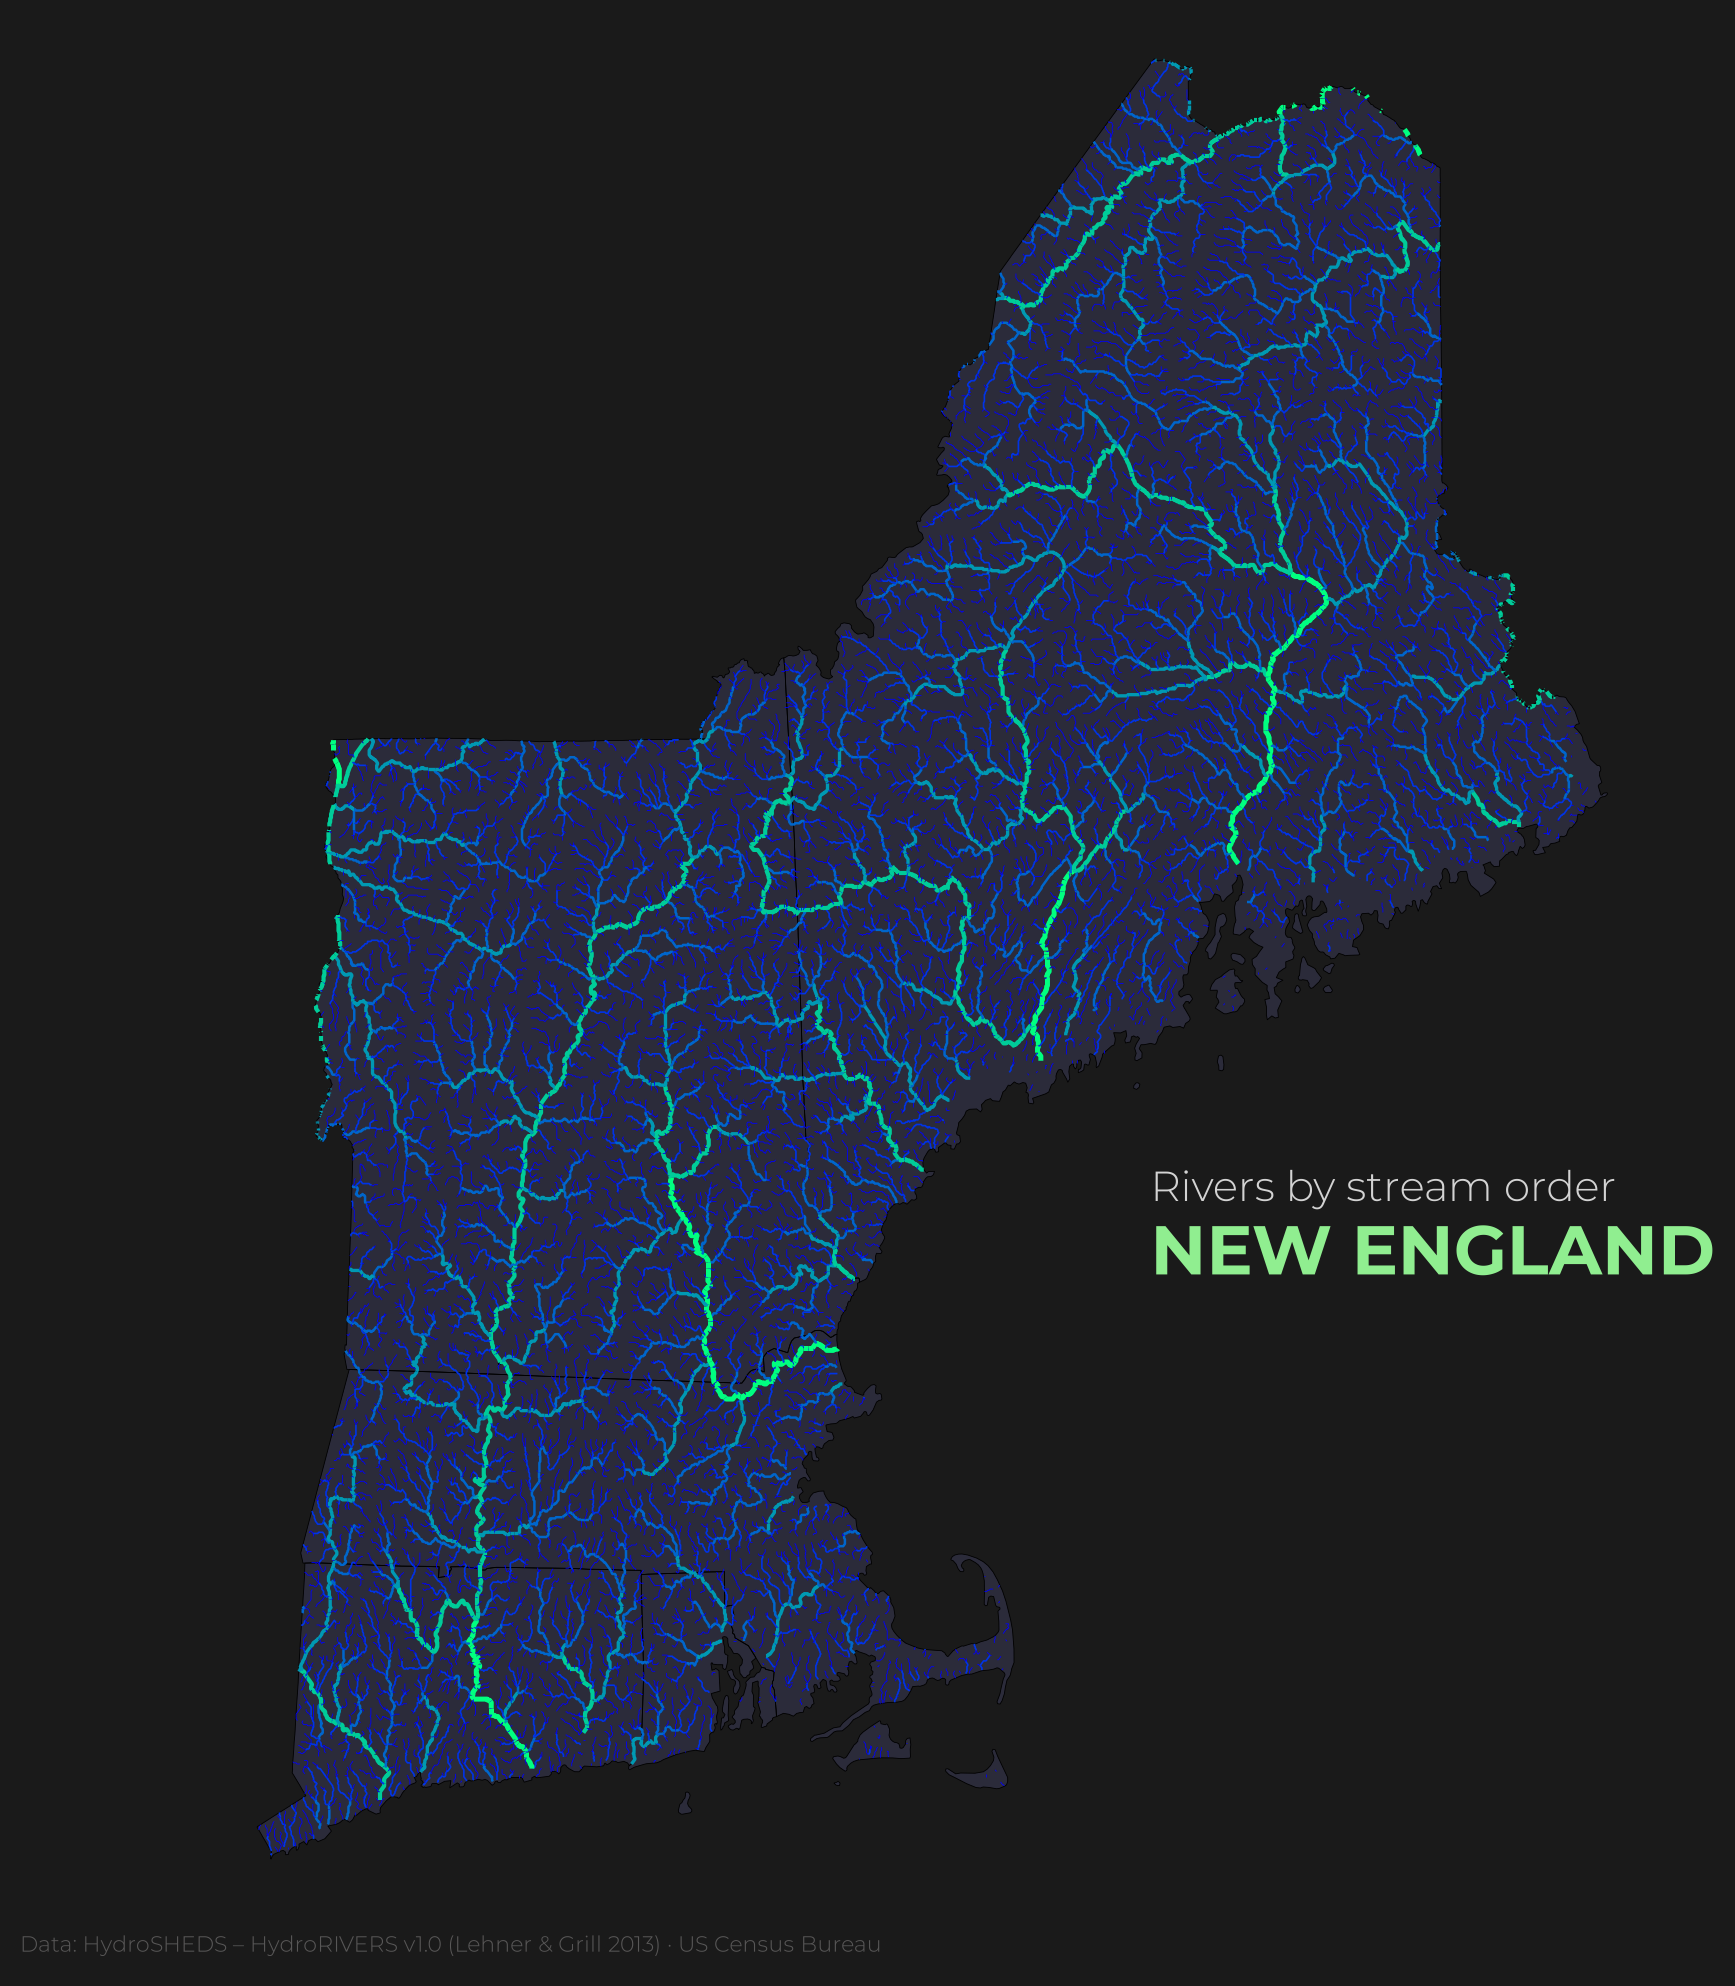

In [1]:

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib import font_manager
import sys
sys.path.append("..")  # the shared canvas lives one folder up, in plate_canvas.py
from plate_canvas import new_plate, finish_plate

font_manager.fontManager.addfont(
    "Fonts/Montserrat-Bold.ttf"
)
font_manager.fontManager.addfont(
    "Fonts/Montserrat-Light.ttf"
)


west_newE = -(73 + 43/60 + 39/3600)
east_newE = -(66 + 56/60 + 59/3600) 
south_newE = (40 + 59/60 + 0/3600)
north_newE = (47 + 27/60 + 35/3600)

ne_box = (west_newE, south_newE, east_newE, north_newE)
#print(ne_box)

rivers_path = "data/HydroRIVERS_v10_na_shp"




rivers = gpd.read_file(rivers_path, bbox=ne_box)
#print(len(rivers))
#print(rivers.columns)
#print(rivers["ORD_STRA"].min())
#print(rivers["ORD_STRA"].max())

order8 = rivers[rivers["ORD_STRA"]==8]
#print(len(order8)) #what is the length of order 8 rivers in the northeastern box?
#print(order8.total_bounds)#where are the order 8 rivers located in the northeastern box? This will give you the bounding box coordinates of the order 8 rivers.

states_path = "data/cb_2025_us_state_5m"

state = gpd.read_file(states_path)
#print(len(state))
#print(state.head())
#print(state.columns)

#print (state["STUSPS"].isin(["MA","RI","NH","ME","CT","VT"]).sum())
ne_states = state[state["STUSPS"].isin(["MA","RI","NH","ME","CT","VT"])]
#print(len(ne_states))

ne_states = ne_states.to_crs(rivers.crs)#here you are converting the coordinate reference system of the northeastern states to match that of the rivers dataset. This is important for accurate spatial analysis and visualization, as both datasets need to be in the same CRS to overlay them correctly.
#ne_states.plot() #this line is commented out, but if uncommented, it would plot the northeastern states using the GeoPandas plotting functionality.

#print(rivers.crs)
#print(ne_states.crs)

ne_rivers = gpd.clip(rivers, ne_states)
#ne_rivers.plot()
#print(len(ne_rivers)) # what is the length of rivers in the northeastern states?
#print(ne_rivers["ORD_STRA"].min()) #what is the minimum order of rivers in the northeastern states?
#print(ne_rivers["ORD_STRA"].max()) #what is the maximum order of rivers in the northeastern states?

order6 = ne_rivers[ne_rivers["ORD_STRA"]==6]
#print(len(order6)) #what is the length of order 6 rivers in the northeastern states
#print(ne_rivers.total_bounds) #where are the rivers located in the northeastern states? This will give you the bounding box coordinates of the rivers in the northeastern states.

#ax = ne_states.plot(color="lightgrey", edgecolor="black", linewidth=0.5)
#ne_rivers.plot(ax=ax, color="blue", linewidth= ne_rivers["ORD_STRA"] * 0.3)
#order6.plot(ax=ax, color="red", linewidth=0.5) helpful for visualizing the order 6 rivers in the northeastern states, but it is commented out. If uncommented, it would plot the order 6 rivers in red on top of the other rivers and states.
#order6.explore(color="red") #this line is commented out, but if uncommented, it would open an interactive map of the order 6 rivers in the northeastern states using the GeoPandas explore functionality.

fig, ax = new_plate()  # same figure size and map box as every other plate
ne_states.plot(ax=ax, color="#2b2b3a", linewidth=0.6)
ne_states.boundary.plot(ax=ax, color="black", linewidth=0.3)
#ne_states.plot(ax=ax, column="STUSPS", cmap="tab20c", categorical=True) #if uncommented, this line would plot the northeastern states with different colors based on their state abbreviation (STUSPS) using the "tab20c" colormap. The categorical=True argument indicates that the data is categorical, which affects how the colors are assigned.
#ne_rivers.plot(ax=ax, color="lightcyan", linewidth=ne_rivers["ORD_STRA"] * 0.3) #this line is commented out, but if uncommented, it would plot the rivers in the northeastern states with a light cyan color and line widths proportional to their stream order (ORD_STRA) multiplied by 0.3.
ne_rivers.plot(ax=ax, column="ORD_STRA", cmap="winter", linewidth=ne_rivers["ORD_STRA"] * 0.3)

#plt.title("Rivers by stream order NEW ENGLAND", color="lightgray", fontfamily="Montserrat", fontsize=18)
#plt.xlabel("Longitude") prints the x-axis label as "Longitude" on the plot, but it is commented out. If uncommented, it would display the label on the x-axis.
#plt.ylabel("Latitude")prints the y-axis label as "Latitude" on the plot, but it is commented out. If uncommented, it would display the label on the y-axis.

# The title, the credits, the map area and the save are the same on every plate,
# so they come from plate_canvas.py. The export is always 1900 x 2040 px.
finish_plate(
    fig, ax,
    kicker="Rivers by stream order",
    title="NEW ENGLAND",
    note="",
    credit="Data: HydroSHEDS – HydroRIVERS v1.0 (Lehner & Grill 2013) · US Census Bureau",
    path="ne_rivers.png",
    title_color="lightgreen",
)
